In [4]:
 import pandas as pd

df = pd.read_csv('C:/Users/pc/Downloads/Bank Customer Churn Prediction.csv')

print(df.shape)          # nombre de lignes et colonnes
print(df.head())         # les 5 premières lignes
print(df.dtypes)         # type de chaque variable
print(df.isnull().sum()) # vérifier valeurs manquantes
print(df['churn'].value_counts()) # distribution de la cible

(10000, 12)
   customer_id  credit_score country  gender  age  tenure    balance  \
0     15634602           619  France  Female   42       2       0.00   
1     15647311           608   Spain  Female   41       1   83807.86   
2     15619304           502  France  Female   42       8  159660.80   
3     15701354           699  France  Female   39       1       0.00   
4     15737888           850   Spain  Female   43       2  125510.82   

   products_number  credit_card  active_member  estimated_salary  churn  
0                1            1              1         101348.88      1  
1                1            0              1         112542.58      0  
2                3            1              0         113931.57      1  
3                2            0              0          93826.63      0  
4                1            1              1          79084.10      0  
customer_id           int64
credit_score          int64
country              object
gender               object

In [5]:
# Supprimer la colonne identifiant (inutile pour le modèle)
df.drop(['customer_id'], axis=1, inplace=True)

# Encoder les variables texte en chiffres (country et gender)
df = pd.get_dummies(df, columns=['country', 'gender'], drop_first=True)

# Séparer X (variables explicatives) et y (variable cible)
X = df.drop('churn', axis=1)
y = df['churn']

print("Colonnes après encodage :", X.columns.tolist())
print("Taille X :", X.shape)
print("Taille y :", y.shape)

Colonnes après encodage : ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'country_Germany', 'country_Spain', 'gender_Male']
Taille X : (10000, 11)
Taille y : (10000,)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Séparer 80% pour entraîner, 20% pour tester
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train : {X_train.shape[0]} lignes")
print(f"Test  : {X_test.shape[0]} lignes")

# Standardiser (mettre toutes les variables à la même échelle)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("Standardisation terminée ✓")

Train : 8000 lignes
Test  : 2000 lignes
Standardisation terminée ✓


In [7]:
from imblearn.over_sampling import SMOTE
import numpy as np

print("Avant SMOTE :", np.bincount(y_train))
# → environ 6370 non-churn vs 1630 churn

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_sc, y_train)

print("Après SMOTE :", np.bincount(y_train_res))
# → 6370 non-churn et 6370 churn (équilibré)

Avant SMOTE : [6370 1630]
Après SMOTE : [6370 6370]


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

modeles = {
    "Arbre de Décision" : DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest"     : RandomForestClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting" : GradientBoostingClassifier(n_estimators=150, random_state=42)
}

for nom, modele in modeles.items():
    modele.fit(X_train_res, y_train_res)
    print(f"{nom} entraîné ✓")

Arbre de Décision entraîné ✓
Random Forest entraîné ✓
Gradient Boosting entraîné ✓


In [9]:
from sklearn.metrics import (classification_report, roc_auc_score,
                              confusion_matrix, f1_score,
                              precision_score, recall_score)

resultats = {}

for nom, modele in modeles.items():
    y_pred  = modele.predict(X_test_sc)
    y_proba = modele.predict_proba(X_test_sc)[:, 1]

    resultats[nom] = {
        'precision' : precision_score(y_test, y_pred),
        'recall'    : recall_score(y_test, y_pred),
        'f1'        : f1_score(y_test, y_pred),
        'auc'       : roc_auc_score(y_test, y_proba),
        'cm'        : confusion_matrix(y_test, y_pred)
    }

    print(f"\n{'='*45}")
    print(f"Modèle : {nom}")
    print(classification_report(y_test, y_pred,
          target_names=['Non-Churn', 'Churn']))
    print(f"ROC-AUC : {resultats[nom]['auc']:.3f}")
    print("Matrice de confusion :")
    print(confusion_matrix(y_test, y_pred))


Modèle : Arbre de Décision
              precision    recall  f1-score   support

   Non-Churn       0.91      0.85      0.88      1593
       Churn       0.53      0.66      0.59       407

    accuracy                           0.81      2000
   macro avg       0.72      0.76      0.73      2000
weighted avg       0.83      0.81      0.82      2000

ROC-AUC : 0.840
Matrice de confusion :
[[1353  240]
 [ 137  270]]

Modèle : Random Forest
              precision    recall  f1-score   support

   Non-Churn       0.90      0.90      0.90      1593
       Churn       0.61      0.59      0.60       407

    accuracy                           0.84      2000
   macro avg       0.75      0.75      0.75      2000
weighted avg       0.84      0.84      0.84      2000

ROC-AUC : 0.849
Matrice de confusion :
[[1441  152]
 [ 168  239]]

Modèle : Gradient Boosting
              precision    recall  f1-score   support

   Non-Churn       0.90      0.91      0.91      1593
       Churn       0.64  

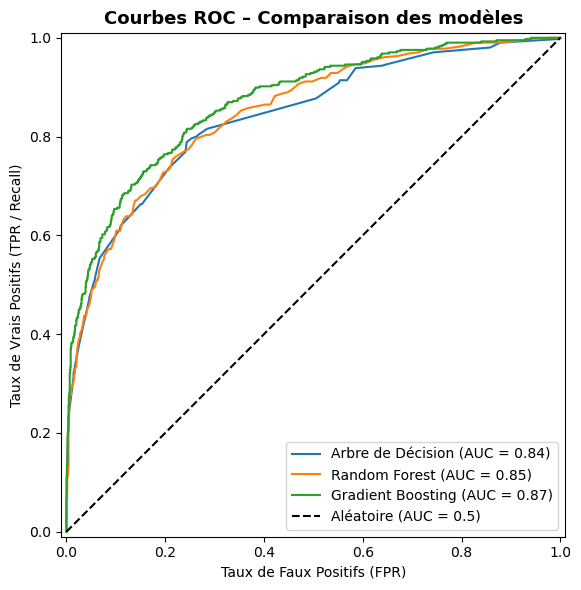

In [11]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Dictionnaire avec tes modèles déjà entraînés
models = {
    "Arbre de Décision"  : modeles["Arbre de Décision"],
    "Random Forest"      : modeles["Random Forest"],
    "Gradient Boosting"  : modeles["Gradient Boosting"]
}

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test_sc, y_test,
        name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.5)')
ax.set_title('Courbes ROC – Comparaison des modèles',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Taux de Faux Positifs (FPR)')
ax.set_ylabel('Taux de Vrais Positifs (TPR / Recall)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [10]:
print("\n=== TABLEAU COMPARATIF ===\n")

for nom, res in resultats.items():
    print(f"{nom}")
    print(f"  Precision : {res['precision']:.3f}")
    print(f"  Recall    : {res['recall']:.3f}")
    print(f"  F1-Score  : {res['f1']:.3f}")
    print(f"  ROC-AUC   : {res['auc']:.3f}")
    print()

# Choisir automatiquement le meilleur selon ROC-AUC
best_name = max(resultats, key=lambda x: resultats[x]['auc'])
print(f"✓ Modèle retenu : {best_name}")
print(f"  ROC-AUC = {resultats[best_name]['auc']:.3f}")


=== TABLEAU COMPARATIF ===

Arbre de Décision
  Precision : 0.529
  Recall    : 0.663
  F1-Score  : 0.589
  ROC-AUC   : 0.840

Random Forest
  Precision : 0.611
  Recall    : 0.587
  F1-Score  : 0.599
  ROC-AUC   : 0.849

Gradient Boosting
  Precision : 0.643
  Recall    : 0.619
  F1-Score  : 0.631
  ROC-AUC   : 0.870

✓ Modèle retenu : Gradient Boosting
  ROC-AUC = 0.870


In [12]:
import pandas as pd
import numpy as np

# Récupérer les probabilités de churn du meilleur modèle
best_model  = modeles[best_name]
proba_churn = best_model.predict_proba(X_test_sc)[:, 1]

# Créer le tableau : variables standardisées + probabilité churn
X_test_df = pd.DataFrame(X_test_sc, columns=X_train.columns)
X_test_df['proba_churn'] = proba_churn

# Créer aussi un tableau avec les vraies valeurs (pour l'interprétation)
X_test_orig = X_test.reset_index(drop=True)
X_test_orig['proba_churn'] = proba_churn

print("Tableau prêt pour le clustering :")
print(f"  Nombre de clients : {len(X_test_df)}")
print(f"  Nombre de variables : {X_test_df.shape[1]}")
print(f"\nProbabilité churn moyenne : {proba_churn.mean():.3f}")
print(f"Probabilité churn min     : {proba_churn.min():.3f}")
print(f"Probabilité churn max     : {proba_churn.max():.3f}")

Tableau prêt pour le clustering :
  Nombre de clients : 2000
  Nombre de variables : 12

Probabilité churn moyenne : 0.278
Probabilité churn min     : 0.010
Probabilité churn max     : 0.991


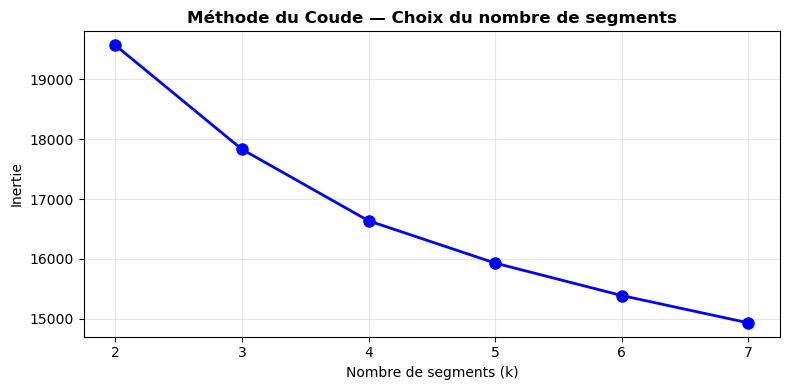


=== RÉSULTATS K-MEANS ===

             mean  count
Segment                 
0        0.207317    792
1        0.270724    704
2        0.400337    504


In [13]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- Trouver le bon k avec la méthode du coude ---
inertias = []
K_range  = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_test_df)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Nombre de segments (k)')
plt.ylabel('Inertie')
plt.title('Méthode du Coude — Choix du nombre de segments',
          fontsize=12, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- Appliquer K-Means avec k=3 ---
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X_test_df['Segment'] = kmeans.fit_predict(X_test_df)

# Réordonner : 0=risque faible, 1=risque moyen, 2=risque élevé
seg_order = X_test_df.groupby('Segment')['proba_churn'].mean().sort_values()
mapping   = {old: new for new, old in enumerate(seg_order.index)}
X_test_df['Segment']      = X_test_df['Segment'].map(mapping)
X_test_orig['Segment']    = X_test_df['Segment'].values

print("\n=== RÉSULTATS K-MEANS ===\n")
print(X_test_df.groupby('Segment')['proba_churn'].agg(['mean', 'count']))

Variance expliquée par l'ACP :
  Composante 1 : 15.1%
  Composante 2 : 10.6%
  Total        : 25.7%


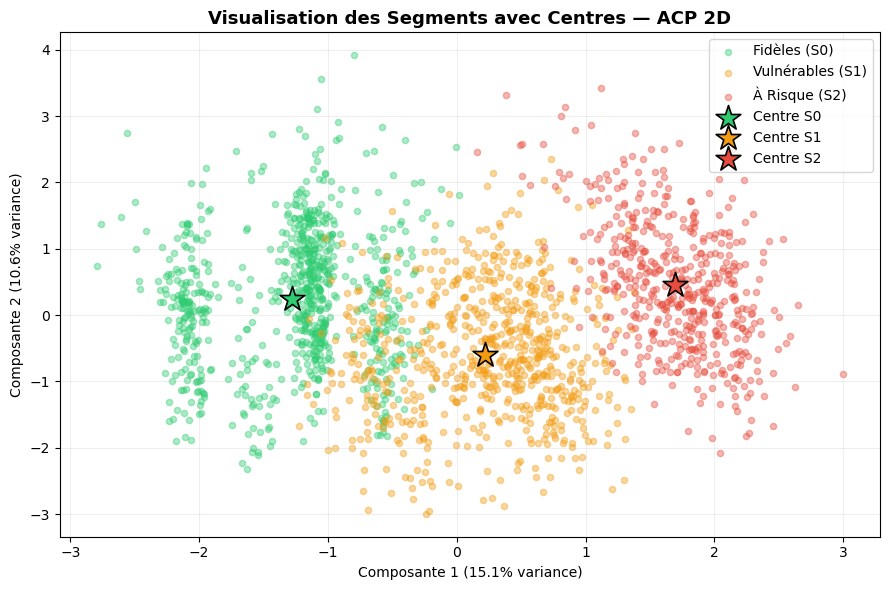

In [17]:

from sklearn.decomposition import PCA
import numpy as np

# Réduire toutes les variables en 2 dimensions
pca    = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_test_sc)

var_exp = pca.explained_variance_ratio_
print(f"Variance expliquée par l'ACP :")
print(f"  Composante 1 : {var_exp[0]*100:.1f}%")
print(f"  Composante 2 : {var_exp[1]*100:.1f}%")
print(f"  Total        : {sum(var_exp)*100:.1f}%")

colors_seg = ['#2ecc71', '#f39c12', '#e74c3c']
labels     = ['Fidèles (S0)', 'Vulnérables (S1)', 'À Risque (S2)']

# Calculer les centres directement depuis les données
# (plus simple et sans erreur)
centres_2d = np.array([
    coords[X_test_df['Segment'] == seg].mean(axis=0)
    for seg in [0, 1, 2]
])

plt.figure(figsize=(9, 6))

# Tracer les points clients
for seg, col, name in zip([0, 1, 2], colors_seg, labels):
    mask = X_test_df['Segment'] == seg
    plt.scatter(coords[mask, 0], coords[mask, 1],
                c=col, alpha=0.4, s=20, label=name)

# Tracer les centres avec une étoile
for seg, col, centre in zip([0, 1, 2], colors_seg, centres_2d):
    plt.scatter(centre[0], centre[1],
                c=col,
                s=350,
                marker='*',
                edgecolors='black',
                linewidths=1.2,
                zorder=5,
                label=f'Centre S{seg}')

plt.title('Visualisation des Segments avec Centres — ACP 2D',
          fontsize=13, fontweight='bold')
plt.xlabel(f'Composante 1 ({var_exp[0]*100:.1f}% variance)')
plt.ylabel(f'Composante 2 ({var_exp[1]*100:.1f}% variance)')
plt.legend(fontsize=10)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
 



=== PROFIL MOYEN PAR SEGMENT ===

           age    balance  products_number  active_member  tenure  \
Segment                                                             
0        38.79    7756.03             1.83           0.52    5.06   
1        38.23  123329.56             1.20           0.52    4.98   
2        39.70  120719.14             1.54           0.51    4.91   

         credit_score  
Segment                
0              647.28  
1              650.06  
2              652.74  

=== EFFECTIFS ET RISQUE ===
Segment 0 : 792 clients (39.6%) — risque moyen = 20.7%
Segment 1 : 704 clients (35.2%) — risque moyen = 27.1%
Segment 2 : 504 clients (25.2%) — risque moyen = 40.0%


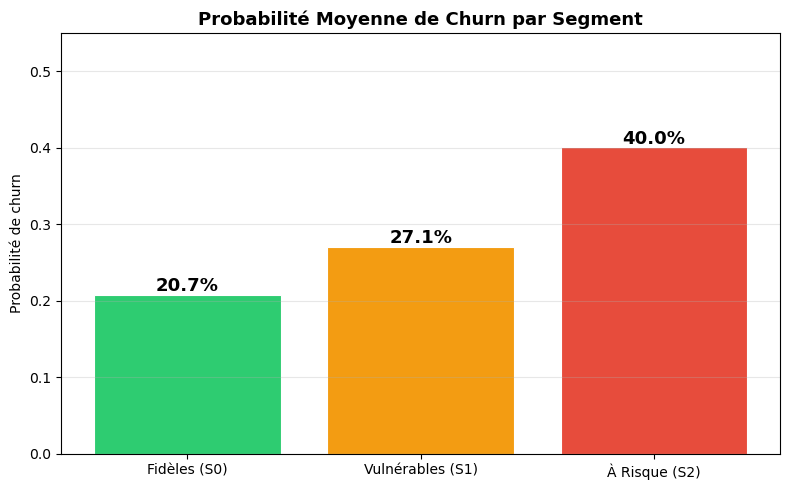

C:\Users\pc\AppData\Local\Temp\ipykernel_16104\3696653395.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(labels, fontsize=8, rotation=10)
C:\Users\pc\AppData\Local\Temp\ipykernel_16104\3696653395.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(labels, fontsize=8, rotation=10)
C:\Users\pc\AppData\Local\Temp\ipykernel_16104\3696653395.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(labels, fontsize=8, rotation=10)
C:\Users\pc\AppData\Local\Temp\ipykernel_16104\3696653395.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(labels, fontsize=8, rotat

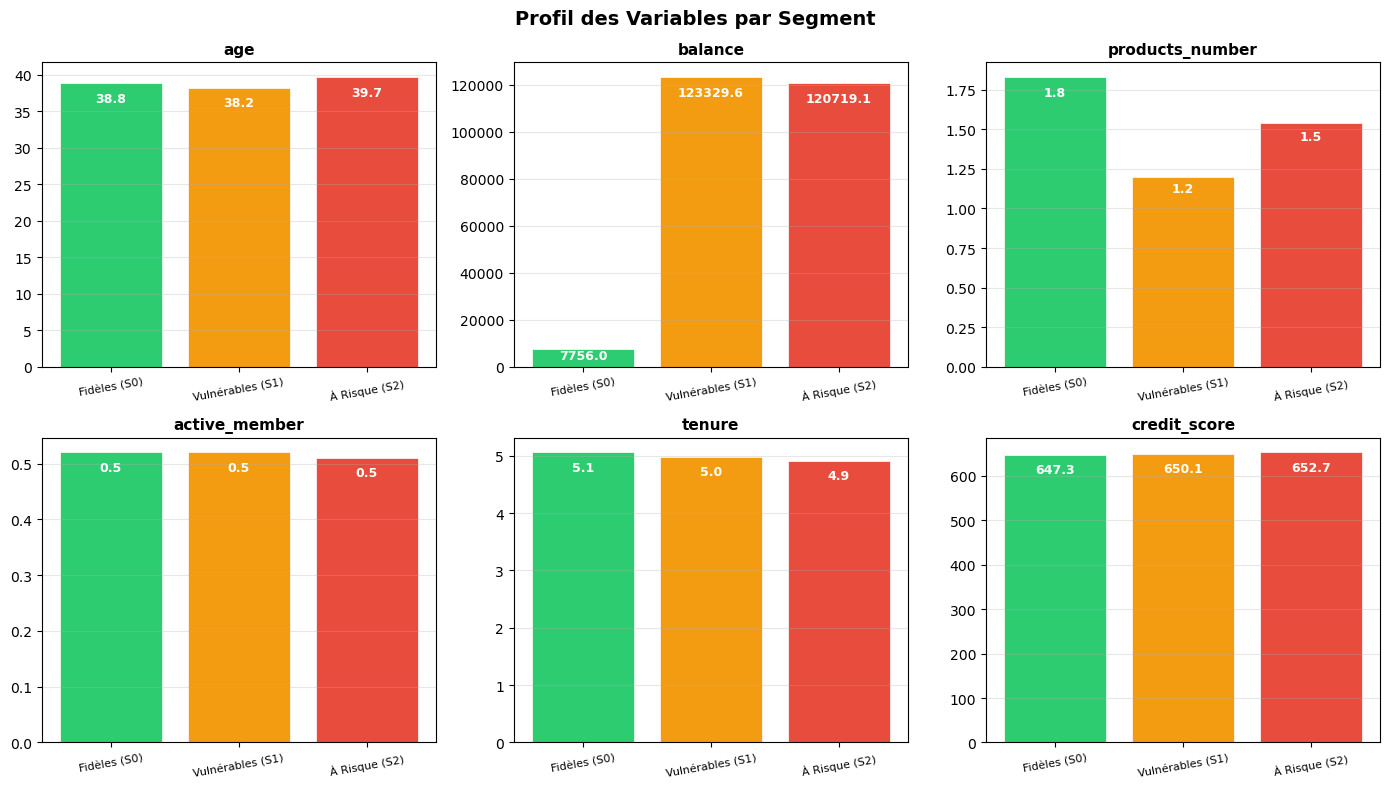

In [18]:
vars_cles = ['age', 'balance', 'products_number',
             'active_member', 'tenure', 'credit_score']

# Tableau profil moyen
profil = X_test_orig.groupby('Segment')[vars_cles].mean().round(2)
print("=== PROFIL MOYEN PAR SEGMENT ===\n")
print(profil)

print("\n=== EFFECTIFS ET RISQUE ===")
for seg in [0, 1, 2]:
    mask = X_test_orig['Segment'] == seg
    n    = mask.sum()
    moy  = X_test_orig.loc[mask, 'proba_churn'].mean()
    print(f"Segment {seg} : {n} clients ({n/len(X_test_orig)*100:.1f}%) "
          f"— risque moyen = {moy:.1%}")

# --- Graphique 1 : probabilité churn par segment ---
seg_stats = X_test_orig.groupby('Segment')['proba_churn'].mean()

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, seg_stats.values,
               color=colors_seg, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, seg_stats.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f'{val:.1%}', ha='center',
             fontsize=13, fontweight='bold')
plt.title('Probabilité Moyenne de Churn par Segment',
          fontsize=13, fontweight='bold')
plt.ylabel('Probabilité de churn')
plt.ylim(0, 0.55)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Graphique 2 : profil des 6 variables par segment ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Profil des Variables par Segment',
             fontsize=14, fontweight='bold')
axes = axes.flatten()

for i, var in enumerate(vars_cles):
    vals = [profil.loc[s, var] for s in [0, 1, 2]]
    bars2 = axes[i].bar(labels, vals,
                        color=colors_seg,
                        edgecolor='white', linewidth=0.5)
    axes[i].set_title(var, fontsize=11, fontweight='bold')
    axes[i].set_xticklabels(labels, fontsize=8, rotation=10)
    axes[i].grid(axis='y', alpha=0.3)
    for bar, val in zip(bars2, vals):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() * 0.97,
                     f'{val:.1f}', ha='center', va='top',
                     fontsize=9, fontweight='bold', color='white')
plt.tight_layout()
plt.show()

In [19]:
print("=" * 60)
print("RÉPONSES AUX QUESTIONS DU PROJET")
print("=" * 60)

# -------------------------------------------------------
print("\nQUESTION 1 :")
print("Existe-t-il plusieurs profils distincts de clients à risque ?")
print("-" * 60)
print("RÉPONSE : OUI. Le K-Means identifie 3 profils clairement distincts.\n")
for seg in [0, 1, 2]:
    mask = X_test_orig['Segment'] == seg
    n    = mask.sum()
    moy  = X_test_orig.loc[mask, 'proba_churn'].mean()
    bal  = X_test_orig.loc[mask, 'balance'].mean()
    prod = X_test_orig.loc[mask, 'products_number'].mean()
    nom  = ["Fidèles", "Vulnérables", "À Risque"][seg]
    print(f"  Segment {seg} — {nom} ({n} clients)")
    print(f"    Risque churn    : {moy:.1%}")
    print(f"    Solde moyen     : {bal:,.0f} €")
    print(f"    Nb produits moy : {prod:.2f}")

# -------------------------------------------------------
print("\nQUESTION 2 :")
print("Les causes du churn sont-elles identiques selon les segments ?")
print("-" * 60)
print("RÉPONSE : NON. Les profils diffèrent sur des variables clés.\n")
print("  Segment 0 (Fidèles) :")
print("    → Solde faible (~7 756€), beaucoup de produits (1.83)")
print("    → Client très engagé avec la banque\n")
print("  Segment 1 (Vulnérables) :")
print("    → Solde élevé (~123 329€), peu de produits (1.20)")
print("    → Client riche mais peu fidélisé\n")
print("  Segment 2 (À Risque) :")
print("    → Solde élevé (~120 719€), taux d'activité le plus faible")
print("    → Client désengagé, à fort risque de départ")

# -------------------------------------------------------
print("\nQUESTION 3 :")
print("Peut-on proposer une stratégie différente par segment ?")
print("-" * 60)
print("RÉPONSE : OUI. Voici les recommandations marketing.\n")

strategies = {
    0: {
        'nom'     : 'Clients Fidèles',
        'risque'  : '~20%',
        'priorite': 'Modérée',
        'action'  : 'Programme fidélité, offres exclusives, newsletter'
    },
    1: {
        'nom'     : 'Clients Vulnérables',
        'risque'  : '~27%',
        'priorite': 'Élevée',
        'action'  : 'Enquête satisfaction, proposer produits complémentaires'
    },
    2: {
        'nom'     : 'Clients À Risque',
        'risque'  : '~40%',
        'priorite': 'URGENTE',
        'action'  : 'Appel conseiller immédiat + offre de rétention personnalisée'
    }
}

for seg, info in strategies.items():
    print(f"  Segment {seg} — {info['nom']}")
    print(f"    Risque     : {info['risque']}")
    print(f"    Priorité   : {info['priorite']}")
    print(f"    Action     : {info['action']}")
    print()

RÉPONSES AUX QUESTIONS DU PROJET

QUESTION 1 :
Existe-t-il plusieurs profils distincts de clients à risque ?
------------------------------------------------------------
RÉPONSE : OUI. Le K-Means identifie 3 profils clairement distincts.

  Segment 0 — Fidèles (792 clients)
    Risque churn    : 20.7%
    Solde moyen     : 7,756 €
    Nb produits moy : 1.83
  Segment 1 — Vulnérables (704 clients)
    Risque churn    : 27.1%
    Solde moyen     : 123,330 €
    Nb produits moy : 1.20
  Segment 2 — À Risque (504 clients)
    Risque churn    : 40.0%
    Solde moyen     : 120,719 €
    Nb produits moy : 1.54

QUESTION 2 :
Les causes du churn sont-elles identiques selon les segments ?
------------------------------------------------------------
RÉPONSE : NON. Les profils diffèrent sur des variables clés.

  Segment 0 (Fidèles) :
    → Solde faible (~7 756€), beaucoup de produits (1.83)
    → Client très engagé avec la banque

  Segment 1 (Vulnérables) :
    → Solde élevé (~123 329€), peu de 